# A rede neural se comporta da mesma forma para todos os públicos?

**Base:** Heart Failure Prediction (918 pacientes, 11 atributos clínicos, alvo `HeartDisease`).

**Pergunta de pesquisa:** *uma rede neural (MLP) treinada nessa base se comporta da mesma forma para todos os públicos (sexo e faixa etária), e o que ela aprendeu em cada um?*

**Como a pergunta é respondida**

| Parte | O que se faz |
|---|---|
| A. Desempenho por subgrupo | AUC, sensibilidade, especificidade e taxa de falsos negativos por sexo e faixa etária, com IC 95% por bootstrap de pacientes |
| B. Conhecimento extraído | Importância por permutação **por subgrupo**, comparação com regressão logística, estabilidade entre repetições, redes treinadas só com um sexo e projeção da camada oculta |
| C. Rigor metodológico | Três tratamentos para o colesterol = 0 (dado ausente codificado como zero), todos dentro da validação cruzada, para evitar vazamento |

**Cuidados de redação:** o alvo é *presença de doença cardíaca* (diagnóstico angiográfico). A idade mínima da base é 28 anos e só 4 pacientes têm menos de 30, por isso as faixas usadas são <45, 45–59 e 60+.

## 0. Configuração

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

SEED = 42
N_SPLITS = 5        # folds da validação cruzada
N_REPEATS = 10      # repetições (com partições e sementes diferentes)
N_PERM = 5          # permutações por variável e por fold
N_BOOT = 1000       # reamostragens bootstrap (métricas por grupo)
N_BOOT_IMP = 300    # reamostragens bootstrap (importâncias)
MAIN_TREATMENT = "impute"   # tratamento do colesterol = 0 usado na análise principal

SEXC = {"F": "#c4571f", "M": "#1f6fb5"}
COL = {"Todos": "#5b6770", "Mulheres": SEXC["F"], "Homens": SEXC["M"],
       "Idade <45": "#8db3d4", "Idade 45-59": "#3f7fb5", "Idade 60+": "#173f66"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})

## 1. Dados

In [2]:
CSV = Path("heart.csv")
if not CSV.exists():
    CSV = "https://raw.githubusercontent.com/jayachandru001/Heart-Failure-Prediction-/main/heart.csv"
df = pd.read_csv(CSV)
assert df.shape == (918, 12), df.shape
assert df.isna().sum().sum() == 0 and df.duplicated().sum() == 0

df["AgeBand"] = pd.cut(df.Age, [0, 44, 59, 200], labels=["<45", "45-59", "60+"]).astype(str)
df["chol0"] = df.Cholesterol.eq(0)   # colesterol = 0 é fisiologicamente impossível -> dado ausente
df["bp0"] = df.RestingBP.eq(0)

FEATS = ["Age", "Sex", "ChestPainType", "RestingBP", "Cholesterol", "FastingBS",
         "RestingECG", "MaxHR", "ExerciseAngina", "Oldpeak", "ST_Slope"]
NUM = ["Age", "RestingBP", "Cholesterol", "FastingBS", "MaxHR", "Oldpeak"]
CAT = ["Sex", "ChestPainType", "RestingECG", "ExerciseAngina", "ST_Slope"]

print(f"Pacientes: {len(df)} | prevalência geral: {df.HeartDisease.mean():.1%}")
print(f"Colesterol = 0: {df.chol0.sum()} | Pressão em repouso = 0: {df.bp0.sum()} | idade mínima: {df.Age.min()}")
resumo = (df.groupby(["Sex", "AgeBand"]).HeartDisease
            .agg(n="size", positivos="sum", prevalencia="mean").round(3))
resumo

Pacientes: 918 | prevalência geral: 55.3%
Colesterol = 0: 172 | Pressão em repouso = 0: 1 | idade mínima: 28


n  positivos  prevalencia
Sex AgeBand                             
F   45-59    101         24        0.238
    60+       50         21        0.420
    <45       42          5        0.119
M   45-59    386        241        0.624
    60+      203        164        0.808
    <45      136         53        0.390

## 2. Pré-processamento e protocolo de validação

**Três tratamentos para o colesterol = 0 (e pressão = 0)**

| Tratamento | O que faz |
|---|---|
| `drop` | remove os 173 registros com zero implausível |
| `impute` | converte os zeros em ausente e imputa a mediana **dentro de cada fold de treino** |
| `impute_flag` | igual ao anterior, mais uma coluna binária "colesterol ausente" |

A exploração anterior mostrou que 88% dos pacientes com colesterol = 0 têm doença (contra 48% dos demais). A ausência **não é aleatória**, e uma rede pode usá-la como atalho. O tratamento `impute_flag` torna esse atalho explícito, o que serve para medir o quanto ele pesa.

**Protocolo:** validação cruzada 5 folds × 10 repetições, estratificada por doença × sexo. Imputação e padronização ficam dentro do `Pipeline`, ajustadas só no treino de cada fold (sem vazamento). Toda previsão é *fora da amostra*: o paciente nunca foi visto pelo modelo que o prevê.

In [3]:
def make_dataset(treatment):
    d = df.copy()
    if treatment == "drop":
        d = d[~(d.chol0 | d.bp0)].copy()
    else:
        d.loc[d.chol0, "Cholesterol"] = np.nan
        d.loc[d.bp0, "RestingBP"] = np.nan
    d = d.reset_index(drop=True)
    X = d[FEATS].copy()
    num = list(NUM)
    if treatment == "impute_flag":
        X["Chol_ausente"] = d.chol0.astype(int)
        num.append("Chol_ausente")
    return X, d.HeartDisease.values, d, num


def make_pipe(model_name, num, seed):
    pre = ColumnTransformer(
        [("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num),
         ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)],
        sparse_threshold=0)
    if model_name == "MLP":
        clf = MLPClassifier(hidden_layer_sizes=(16, 8), alpha=1e-2, max_iter=1000,
                            early_stopping=True, n_iter_no_change=20, random_state=seed)
    else:
        clf = LogisticRegression(C=1.0, max_iter=2000)
    return Pipeline([("pre", pre), ("clf", clf)])


def group_masks(d):
    g = {"Todos": np.ones(len(d), bool),
         "Mulheres": (d.Sex == "F").values, "Homens": (d.Sex == "M").values}
    for a in ["<45", "45-59", "60+"]:
        g["Idade " + a] = (d.AgeBand == a).values
    return g


def run_cv(treatment, model_name, importance=True, subset=None):

    X, y, d, num = make_dataset(treatment)
    if subset is not None:
        m = subset(d).values
        X, y, d = X[m].reset_index(drop=True), y[m], d[m].reset_index(drop=True)
    strat = y * 2 + (d.Sex == "M").astype(int).values
    cv = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED)
    n = len(y)
    oof = np.zeros((N_REPEATS, n))
    perm = {f: np.zeros((N_REPEATS, N_PERM, n)) for f in X.columns} if importance else None
    rng = np.random.default_rng(SEED)
    for i, (tr, te) in enumerate(cv.split(X, strat)):
        r = i // N_SPLITS
        pipe = make_pipe(model_name, num, SEED + i).fit(X.iloc[tr], y[tr])
        Xte = X.iloc[te]
        oof[r, te] = pipe.predict_proba(Xte)[:, 1]
        if importance:
            for f in X.columns:
                for k in range(N_PERM):
                    Xp = Xte.copy()
                    Xp[f] = rng.permutation(Xp[f].values)
                    perm[f][r, k, te] = pipe.predict_proba(Xp)[:, 1]
    res = dict(X=X, y=y, d=d, num=num, oof=oof, perm=perm)
    if importance:
        res["pperm"] = {f: perm[f].mean(axis=(0, 1)) for f in perm}
    return res

## 3. Os três tratamentos do colesterol: Desempenho

Para a realização da comparação, o AUC é reportado em três populações:
todos os pacientes do tratamento, só os pacientes com dados completos ("limpos", comuns aos três) e só os pacientes com colesterol = 0 (não existem em `drop`).

In [4]:
RES = {}
for tr in ["drop", "impute", "impute_flag"]:
    for m in ["MLP", "LR"]:
        RES[(tr, m)] = run_cv(tr, m, importance=True)

rows = []
for (tr, m), res in RES.items():
    y, p, d = res["y"], res["oof"].mean(0), res["d"]
    clean = ~(d.chol0 | d.bp0).values
    rows.append({"Tratamento": tr, "Modelo": m, "n": len(y),
                 "AUC todos": roc_auc_score(y, p),
                 "AUC limpos": roc_auc_score(y[clean], p[clean]),
                 "AUC chol=0": roc_auc_score(y[~clean], p[~clean]) if (~clean).any() else np.nan})
TRAT = pd.DataFrame(rows).round(3)
TRAT

,Tratamento,Modelo,n,AUC todos,AUC limpos,AUC chol=0
0,drop,MLP,746,0.918,0.918,NaN
1,drop,LR,746,0.926,0.926,NaN
2,impute,MLP,918,0.918,0.917,0.819
3,impute,LR,918,0.922,0.923,0.855
4,impute_flag,MLP,918,0.922,0.916,0.805
5,impute_flag,LR,918,0.928,0.925,0.826


## 4. Parte A: a rede se comporta da mesma forma para todos os públicos?

Análise principal com o tratamento `MAIN_TREATMENT`, limiar de decisão fixo em 0,5.
As previsões de cada paciente são a média das 10 repetições da validação cruzada (todas fora da amostra).
O IC 95% vem de bootstrap **de pacientes**.

In [5]:
MAIN = RES[(MAIN_TREATMENT, "MLP")]
y, p, d = MAIN["y"], MAIN["oof"].mean(0), MAIN["d"]

GR = group_masks(d)
GRX = {f"{sl} {a}": ((d.Sex == s) & (d.AgeBand == a)).values
       for s, sl in [("F", "Mulheres"), ("M", "Homens")] for a in ["<45", "45-59", "60+"]}


def metrics(yy, pp, thr=0.5):
    pred = pp >= thr
    tp, fn = (pred & (yy == 1)).sum(), (~pred & (yy == 1)).sum()
    tn, fp = (~pred & (yy == 0)).sum(), (pred & (yy == 0)).sum()
    return dict(AUC=roc_auc_score(yy, pp) if len(np.unique(yy)) == 2 else np.nan,
                Sens=tp / (tp + fn) if tp + fn else np.nan,
                Espec=tn / (tn + fp) if tn + fp else np.nan)


def group_boot(yy, pp, rng, B=N_BOOT):
    out = {"AUC": [], "Sens": [], "Espec": []}
    n = len(yy)
    for _ in range(B):
        i = rng.integers(0, n, n)
        a, b = yy[i], pp[i]
        if a.min() == a.max():
            for k in out:
                out[k].append(np.nan)
            continue
        pred = b >= 0.5
        out["AUC"].append(roc_auc_score(a, b))
        out["Sens"].append(pred[a == 1].mean())
        out["Espec"].append((~pred[a == 0]).mean())
    return {k: np.array(v) for k, v in out.items()}


rng = np.random.default_rng(SEED)
BOOT, ROWS = {}, []
for name, m in {**GR, **GRX}.items():
    BOOT[name] = group_boot(y[m], p[m], rng)
    mt = metrics(y[m], p[m])
    row = {"Grupo": name, "n": int(m.sum()), "n_pos": int(y[m].sum()),
           "Prev_obs": y[m].mean(), "Prob_media": p[m].mean()}
    for k in ["AUC", "Sens", "Espec"]:
        lo, hi = np.nanpercentile(BOOT[name][k], [2.5, 97.5])
        row.update({k: mt[k], k + "_lo": lo, k + "_hi": hi})
    row["FNR"] = 1 - row["Sens"]
    ROWS.append(row)
TAB = pd.DataFrame(ROWS).set_index("Grupo")


def fmt(r, k):
    return f"{r[k]:.2f} [{r[k + '_lo']:.2f}–{r[k + '_hi']:.2f}]"


show = pd.DataFrame({"n": TAB.n, "n_pos": TAB.n_pos,
                     "Prev. obs.": TAB.Prev_obs.round(2), "Prob. média prevista": TAB.Prob_media.round(2),
                     "AUC": TAB.apply(lambda r: fmt(r, "AUC"), axis=1),
                     "Sensibilidade": TAB.apply(lambda r: fmt(r, "Sens"), axis=1),
                     "Especificidade": TAB.apply(lambda r: fmt(r, "Espec"), axis=1)})
show["Aviso"] = np.where(TAB.n_pos < 10, "n_pos<10: não interpretar", "")
show

,n,n_pos,Prev. obs.,Prob. média prevista,AUC,Sensibilidade,Especificidade,Aviso
Grupo,,,,,,,,
Todos,918,508,0.55,0.55,0.92 [0.90–0.94],0.88 [0.85–0.91],0.80 [0.76–0.84],
Mulheres,193,50,0.26,0.36,0.91 [0.86–0.95],0.76 [0.64–0.87],0.85 [0.78–0.91],
Homens,725,458,0.63,0.60,0.91 [0.89–0.93],0.89 [0.86–0.92],0.78 [0.73–0.82],
Idade <45,178,58,0.33,0.35,0.95 [0.91–0.98],0.69 [0.56–0.81],0.95 [0.91–0.98],
Idade 45-59,487,265,0.54,0.55,0.91 [0.88–0.93],0.87 [0.83–0.91],0.80 [0.75–0.85],
Idade 60+,253,185,0.73,0.70,0.87 [0.82–0.92],0.95 [0.91–0.98],0.53 [0.41–0.64],
Mulheres <45,42,5,0.12,0.21,0.99 [0.95–1.00],0.60 [0.00–1.00],0.97 [0.91–1.00],n_pos<10: não interpretar
Mulheres 45-59,101,24,0.24,0.37,0.89 [0.81–0.96],0.75 [0.58–0.91],0.84 [0.76–0.92],
Mulheres 60+,50,21,0.42,0.49,0.86 [0.73–0.94],0.81 [0.63–0.95],0.69 [0.50–0.84],


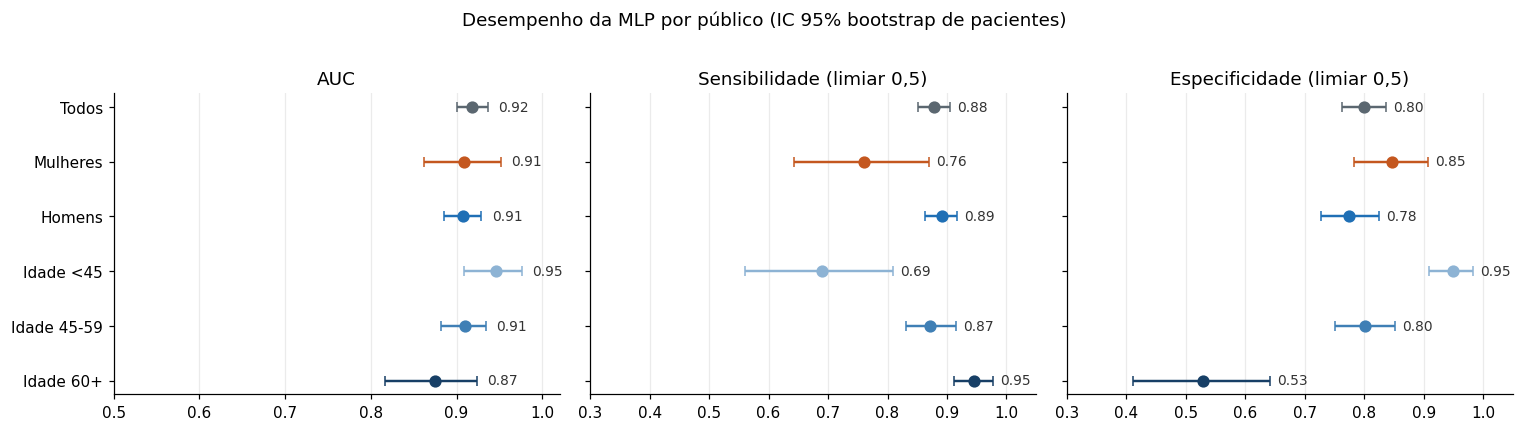

In [6]:
order = ["Todos", "Mulheres", "Homens", "Idade <45", "Idade 45-59", "Idade 60+"]
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, key, title in zip(axs, ["AUC", "Sens", "Espec"], ["AUC", "Sensibilidade (limiar 0,5)", "Especificidade (limiar 0,5)"]):
    for i, g in enumerate(order):
        v, lo, hi = TAB.loc[g, key], TAB.loc[g, key + "_lo"], TAB.loc[g, key + "_hi"]
        ax.errorbar(v, i, xerr=[[v - lo], [hi - v]], fmt="o", color=COL[g], capsize=3, ms=7, lw=1.6)
        ax.text(hi + 0.012, i, f"{v:.2f}", va="center", fontsize=9, color="#333")
    ax.set_yticks(range(len(order)))
    ax.set_yticklabels(order)
    ax.set_title(title)
    ax.grid(axis="x", alpha=0.25)
axs[0].invert_yaxis()
axs[0].set_xlim(0.5, 1.02)
axs[1].set_xlim(0.3, 1.05)
axs[2].set_xlim(0.3, 1.05)
fig.suptitle("Desempenho da MLP por público (IC 95% bootstrap de pacientes)", y=1.02)
plt.tight_layout()
plt.show()

**Diferenças entre públicos** (IC 95% da diferença; quando o IC inclui 0, não há evidência de diferença nesta amostra):

In [ ]:
pairs = [("Mulheres", "Homens"), ("Idade <45", "Idade 60+"), ("Idade <45", "Idade 45-59"), ("Idade 45-59", "Idade 60+")]
rows = []
for a, b in pairs:
    for k, nome in [("AUC", "AUC"), ("Sens", "Sensibilidade"), ("Espec", "Especificidade")]:
        dif = BOOT[a][k] - BOOT[b][k]
        lo, hi = np.nanpercentile(dif, [2.5, 97.5])
        pt = TAB.loc[a, k] - TAB.loc[b, k]
        rows.append({"Comparação": f"{a} − {b}", "Métrica": nome, "Diferença": round(pt, 3),
                     "IC 95%": f"[{lo:.3f}; {hi:.3f}]", "Exclui 0?": "sim" if (lo > 0 or hi < 0) else "não"})
DIF = pd.DataFrame(rows)
DIF

,Comparação,Métrica,Diferença,IC 95%,Exclui 0?
0,Mulheres − Homens,AUC,0.001,[-0.050; 0.049],não
1,Mulheres − Homens,Sensibilidade,-0.131,[-0.248; -0.015],sim
2,Mulheres − Homens,Especificidade,0.071,[-0.008; 0.144],não
3,Idade <45 − Idade 60+,AUC,0.071,[0.014; 0.135],sim
4,Idade <45 − Idade 60+,Sensibilidade,-0.256,[-0.391; -0.128],sim
5,Idade <45 − Idade 60+,Especificidade,0.421,[0.299; 0.545],sim
6,Idade <45 − Idade 45-59,AUC,0.036,[-0.010; 0.077],não
7,Idade <45 − Idade 45-59,Sensibilidade,-0.182,[-0.319; -0.056],sim
8,Idade <45 − Idade 45-59,Especificidade,0.148,[0.080; 0.207],sim
9,Idade 45-59 − Idade 60+,AUC,0.035,[-0.022; 0.099],não


## 5. Parte B: o que a rede aprendeu em cada público?

**Importância por permutação.** Para cada variável, embaralham-se seus valores no fold de teste e mede-se a queda do AUC *dentro de cada subgrupo*. Quanto maior a queda, mais a rede depende da variável para aquele público. Isso verifica se "a mesma rede usa as mesmas informações para mulheres e homens?". A estimativa usa as previsões médias de 10 repetições × 5 permutações, e o IC vem de bootstrap de pacientes.

In [ ]:
def imp_point(res, mask):
    yy, base = res["y"][mask], res["oof"].mean(0)[mask]
    a0 = roc_auc_score(yy, base)
    return pd.Series({f: a0 - roc_auc_score(yy, res["pperm"][f][mask]) for f in res["pperm"]})


def imp_boot(res, mask, B=N_BOOT_IMP, seed=SEED):
    rg = np.random.default_rng(seed)
    idx = np.where(mask)[0]
    y_, base = res["y"], res["oof"].mean(0)
    feats = list(res["pperm"])
    out = np.full((B, len(feats)), np.nan)
    for b in range(B):
        i = rg.choice(idx, len(idx))
        if y_[i].min() == y_[i].max():
            continue
        a0 = roc_auc_score(y_[i], base[i])
        for j, f in enumerate(feats):
            out[b, j] = a0 - roc_auc_score(y_[i], res["pperm"][f][i])
    return pd.DataFrame(out, columns=feats)


def imp_by_repeat(res, mask):
    yy = res["y"][mask]
    rows = []
    for r in range(N_REPEATS):
        a0 = roc_auc_score(yy, res["oof"][r][mask])
        rows.append({f: a0 - np.mean([roc_auc_score(yy, res["perm"][f][r, k][mask]) for k in range(N_PERM)])
                     for f in res["perm"]})
    return pd.DataFrame(rows)


LR_MAIN = RES[(MAIN_TREATMENT, "LR")]
IMP = {"MLP": {g: imp_point(MAIN, m) for g, m in GR.items()},
       "LR": {g: imp_point(LR_MAIN, m) for g, m in GR.items()}}
IMPB = {g: imp_boot(MAIN, GR[g]) for g in ["Mulheres", "Homens"]}

H = pd.DataFrame(IMP["MLP"])[order]
H = H.loc[H["Todos"].sort_values(ascending=False).index]
H.round(3)

,Todos,Mulheres,Homens,Idade <45,Idade 45-59,Idade 60+
ST_Slope,0.025,0.035,0.030,0.022,0.036,0.017
ChestPainType,0.014,0.013,0.016,0.034,0.008,0.026
Sex,0.009,0.001,-0.000,0.005,0.010,0.010
FastingBS,0.007,0.019,0.005,0.011,0.006,0.015
Oldpeak,0.004,0.008,0.004,-0.004,0.005,0.014
ExerciseAngina,0.004,0.011,0.004,-0.003,0.002,0.017
RestingBP,0.000,-0.000,0.000,0.000,0.001,-0.002
RestingECG,0.000,0.002,-0.000,0.001,0.001,-0.003
MaxHR,-0.001,-0.009,0.002,-0.005,-0.001,0.003
Cholesterol,-0.001,0.002,-0.001,-0.004,-0.001,-0.001


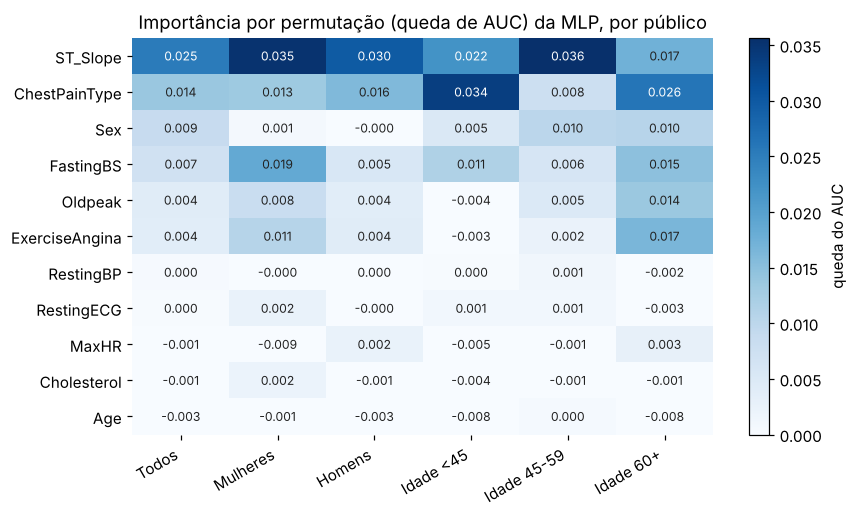

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.8))
im = ax.imshow(H.values, cmap="Blues", aspect="auto", vmin=0)
ax.set_xticks(range(len(H.columns)))
ax.set_xticklabels(H.columns, rotation=30, ha="right")
ax.set_yticks(range(len(H.index)))
ax.set_yticklabels(H.index)
vmax = np.nanmax(H.values)
for i in range(H.shape[0]):
    for j in range(H.shape[1]):
        v = H.values[i, j]
        ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=8,
                color="white" if v > 0.55 * vmax else "#222")
ax.set_title("Importância por permutação (queda de AUC) da MLP, por público")
ax.spines[:].set_visible(False)
plt.colorbar(im, ax=ax, label="queda do AUC")
plt.tight_layout()
plt.show()

**Mulheres × homens**, com IC 95% (bootstrap de pacientes). A diferença `F − M` positiva significa que a rede depende mais da variável para mulheres.

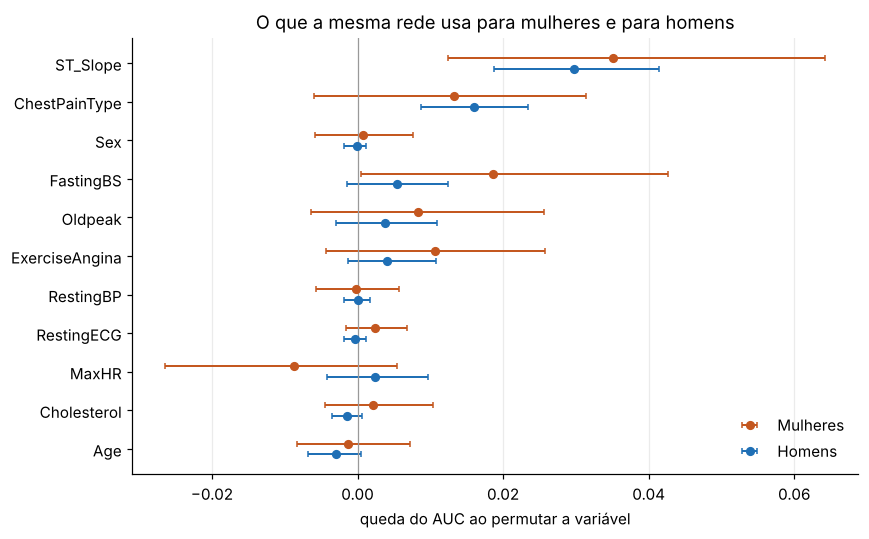

,Variável,F − M,IC 95%,Exclui 0?
0,ST_Slope,0.005,[-0.021; 0.037],não
1,ChestPainType,-0.003,[-0.024; 0.018],não
2,Sex,0.001,[-0.006; 0.008],não
3,FastingBS,0.013,[-0.006; 0.040],não
4,Oldpeak,0.004,[-0.011; 0.024],não
5,ExerciseAngina,0.007,[-0.010; 0.024],não
6,RestingBP,-0.000,[-0.006; 0.006],não
7,RestingECG,0.003,[-0.002; 0.007],não
8,MaxHR,-0.011,[-0.030; 0.005],não
9,Cholesterol,0.004,[-0.004; 0.013],não


In [ ]:
feats_ord = list(H.index)
fig, ax = plt.subplots(figsize=(8, 5))
for j, (g, s) in enumerate([("Mulheres", "F"), ("Homens", "M")]):
    for i, f in enumerate(feats_ord):
        v = IMP["MLP"][g][f]
        lo, hi = np.nanpercentile(IMPB[g][f], [2.5, 97.5])
        ax.errorbar(v, i + (j - 0.5) * 0.28, xerr=[[max(v - lo, 0)], [max(hi - v, 0)]], fmt="o",
                    color=SEXC[s], capsize=2, ms=5, lw=1.3, label=g if i == 0 else None)
ax.set_yticks(range(len(feats_ord)))
ax.set_yticklabels(feats_ord)
ax.invert_yaxis()
ax.axvline(0, color="#999", lw=0.8)
ax.set_xlabel("queda do AUC ao permutar a variável")
ax.set_title("O que a mesma rede usa para mulheres e para homens")
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

rows = []
for f in feats_ord:
    dif = IMPB["Mulheres"][f] - IMPB["Homens"][f]
    lo, hi = np.nanpercentile(dif, [2.5, 97.5])
    pt = IMP["MLP"]["Mulheres"][f] - IMP["MLP"]["Homens"][f]
    rows.append({"Variável": f, "F − M": round(pt, 3), "IC 95%": f"[{lo:.3f}; {hi:.3f}]",
                 "Exclui 0?": "sim" if (lo > 0 or hi < 0) else "não"})
DIF_IMP = pd.DataFrame(rows)
DIF_IMP

### 5.1 Estabilidade: as conclusões dependem da semente?

Em redes pequenas, a importância muda de uma execução para outra. Para cada público, calcula-se, em cada uma das 10 repetições (partições e inicializações diferentes), as 3 variáveis mais importantes e a **fração das repetições** em que cada uma aparece entre elas.

In [ ]:
rows = {}
for g in ["Mulheres", "Homens", "Idade <45", "Idade 45-59", "Idade 60+"]:
    ir = imp_by_repeat(MAIN, GR[g])
    top3 = ir.apply(lambda r: set(r.sort_values(ascending=False).index[:3]), axis=1)
    freq = pd.Series({f: np.mean([f in t for t in top3]) for f in ir.columns})
    rows[g] = freq
TOP3 = pd.DataFrame(rows)
TOP3 = TOP3[TOP3.max(axis=1) > 0].sort_values("Mulheres", ascending=False)
TOP3.round(2)

,Mulheres,Homens,Idade <45,Idade 45-59,Idade 60+
ST_Slope,1.0,1.0,1.0,1.0,1.0
Oldpeak,0.7,0.8,0.3,0.7,0.8
ChestPainType,0.7,0.8,1.0,0.5,0.8
FastingBS,0.4,0.0,0.7,0.0,0.1
ExerciseAngina,0.2,0.2,0.0,0.1,0.1
Sex,0.0,0.0,0.0,0.4,0.1
MaxHR,0.0,0.2,0.0,0.3,0.1


### 5.2 Concordância com a regressão logística e entre públicos

Correlação de postos (Spearman) entre os rankings de importância. Se a rede e um modelo linear simples elegem as mesmas variáveis, a interpretação é mais confiável.

In [ ]:
def rho(a, b):
    return spearmanr(a.values, b.loc[a.index].values)[0]


rows = [{"Comparação": "MLP: mulheres × homens", "rho": rho(IMP["MLP"]["Mulheres"], IMP["MLP"]["Homens"])},
        {"Comparação": "MLP: <45 × 60+", "rho": rho(IMP["MLP"]["Idade <45"], IMP["MLP"]["Idade 60+"])},
        {"Comparação": "LR: mulheres × homens", "rho": rho(IMP["LR"]["Mulheres"], IMP["LR"]["Homens"])},
        {"Comparação": "LR: <45 × 60+", "rho": rho(IMP["LR"]["Idade <45"], IMP["LR"]["Idade 60+"])}]
rows += [{"Comparação": f"MLP × LR ({g})", "rho": rho(IMP["MLP"][g], IMP["LR"][g])} for g in order]
CONC = pd.DataFrame(rows)
CONC["rho"] = CONC.rho.round(2)
mlp_auc = {g: TAB.loc[g, "AUC"] for g in order}
lr_p = LR_MAIN["oof"].mean(0)
CONC_AUC = pd.DataFrame({"AUC MLP": mlp_auc,
                         "AUC LR": {g: roc_auc_score(y[GR[g]], lr_p[GR[g]]) for g in order}}).round(3)
display(CONC)
display(CONC_AUC)

,Comparação,rho
0,MLP: mulheres × homens,0.77
1,MLP: <45 × 60+,0.66
2,LR: mulheres × homens,0.81
3,LR: <45 × 60+,0.74
4,MLP × LR (Todos),0.85
5,MLP × LR (Mulheres),0.85
6,MLP × LR (Homens),0.85
7,MLP × LR (Idade <45),0.69
8,MLP × LR (Idade 45-59),0.85
9,MLP × LR (Idade 60+),0.94


,AUC MLP,AUC LR
Todos,0.918,0.922
Mulheres,0.909,0.911
Homens,0.908,0.910
Idade <45,0.946,0.960
Idade 45-59,0.910,0.910
Idade 60+,0.874,0.877


### 5.3 Redes treinadas só com um sexo

A importância acima descreve **a mesma rede** avaliada em cada público. Aqui treina-se uma rede **só com mulheres** e outra **só com homens** (mesma validação cruzada), para ver (i) se uma rede específica prevê melhor para seu público e (ii) o que ela aprende quando só vê aquele público. Com 193 mulheres, os resultados são mais ruidosos.

In [ ]:
SEX_MODELS = {}
for s, lab in [("F", "Mulheres"), ("M", "Homens")]:
    r_ = run_cv(MAIN_TREATMENT, "MLP", importance=True, subset=lambda dd, s=s: dd.Sex == s)
    SEX_MODELS[lab] = r_

LR_SX = {lab: run_cv(MAIN_TREATMENT, "LR", importance=False, subset=lambda dd, s=s: dd.Sex == s)
         for s, lab in [("F", "Mulheres"), ("M", "Homens")]}

rng = np.random.default_rng(SEED + 1)
rows = []
for lab, r_ in SEX_MODELS.items():
    yy, pp = r_["y"], r_["oof"].mean(0)
    b = group_boot(yy, pp, rng)
    mt = metrics(yy, pp)
    gl = metrics(y[GR[lab]], p[GR[lab]])
    rows.append({"Público": lab, "n": len(yy),
                 "AUC rede específica": f"{mt['AUC']:.2f} [{np.nanpercentile(b['AUC'], 2.5):.2f}–{np.nanpercentile(b['AUC'], 97.5):.2f}]",
                 "AUC rede global": f"{gl['AUC']:.2f} [{TAB.loc[lab, 'AUC_lo']:.2f}–{TAB.loc[lab, 'AUC_hi']:.2f}]",
                 "AUC LR específica": round(roc_auc_score(LR_SX[lab]["y"], LR_SX[lab]["oof"].mean(0)), 2),
                 "Sens. específica": round(mt["Sens"], 2), "Sens. global": round(gl["Sens"], 2),
                 "Espec. específica": round(mt["Espec"], 2), "Espec. global": round(gl["Espec"], 2)})
display(pd.DataFrame(rows))

full = np.ones(len(SEX_MODELS["Mulheres"]["y"]), bool)
IMP_SX = pd.DataFrame({lab: imp_point(r_, np.ones(len(r_["y"]), bool)) for lab, r_ in SEX_MODELS.items()})
IMP_SX = IMP_SX.drop(index="Sex").loc[H.index.drop("Sex")]
print("Importância (queda de AUC) em redes treinadas só com cada sexo:")
display(IMP_SX.round(3))
print("Spearman entre as importâncias da rede só-mulheres e só-homens: %.2f" % rho(IMP_SX["Mulheres"], IMP_SX["Homens"]))
print("Spearman rede só-mulheres × rede global avaliada em mulheres: %.2f" % rho(IMP_SX["Mulheres"], IMP["MLP"]["Mulheres"].drop("Sex")))
print("Spearman rede só-homens × rede global avaliada em homens: %.2f" % rho(IMP_SX["Homens"], IMP["MLP"]["Homens"].drop("Sex")))

,Público,n,AUC rede específica,AUC rede global,AUC LR específica,Sens. específica,Sens. global,Espec. específica,Espec. global
0,Mulheres,193,0.78 [0.71–0.87],0.91 [0.86–0.95],0.90,0.3,0.76,0.97,0.85
1,Homens,725,0.90 [0.87–0.92],0.91 [0.89–0.93],0.91,0.9,0.89,0.77,0.78


Importância (queda de AUC) em redes treinadas só com cada sexo:


,Mulheres,Homens
ST_Slope,0.028,0.028
ChestPainType,0.026,0.014
FastingBS,0.034,0.008
Oldpeak,0.034,0.008
ExerciseAngina,0.023,0.005
RestingBP,0.020,-0.001
RestingECG,0.006,-0.000
MaxHR,-0.003,0.004
Cholesterol,0.007,-0.001
Age,0.008,-0.002


Spearman entre as importâncias da rede só-mulheres e só-homens: 0.68
Spearman rede só-mulheres × rede global avaliada em mulheres: 0.76
Spearman rede só-homens × rede global avaliada em homens: 0.98


**Regressão logística ajustada separadamente por sexo** (coeficientes das variáveis padronizadas; sinal = direção do efeito sobre a chance de doença):

In [ ]:
coefs = {}
for s, lab in [("F", "Mulheres"), ("M", "Homens")]:
    X, y_, d_, num = make_dataset(MAIN_TREATMENT)
    m = (d_.Sex == s).values
    pipe = make_pipe("LR", num, SEED).fit(X[m], y_[m])
    names = pipe.named_steps["pre"].get_feature_names_out()
    coefs[lab] = pd.Series(pipe.named_steps["clf"].coef_[0], index=[n.split("__")[1] for n in names])
COEF = pd.DataFrame(coefs).drop(index=["Sex_F", "Sex_M"])
COEF = COEF.loc[COEF.abs().max(axis=1).sort_values(ascending=False).index]
COEF.round(2).head(12)

,Mulheres,Homens
ST_Slope_Up,-1.28,-1.04
ST_Slope_Flat,0.93,1.26
ChestPainType_ASY,1.11,1.21
FastingBS,0.87,0.47
ChestPainType_ATA,-0.38,-0.68
ChestPainType_TA,-0.56,-0.09
RestingBP,0.51,-0.08
ExerciseAngina_Y,0.34,0.45
Oldpeak,0.37,0.42
ExerciseAngina_N,-0.34,-0.38


## 6. Sensibilidade ao tratamento do colesterol = 0

O que a rede "aprende" sobre o colesterol muda conforme o tratamento? Importância (queda de AUC, todos os pacientes) para cada tratamento, na MLP:

In [ ]:
rows = {}
for tr in ["drop", "impute", "impute_flag"]:
    res = RES[(tr, "MLP")]
    rows[tr] = imp_point(res, np.ones(len(res["y"]), bool))
SENS = pd.DataFrame(rows)
SENS = SENS.loc[SENS.max(axis=1).sort_values(ascending=False).index]
display(SENS.round(3))

fm = RES[("impute_flag", "MLP")]
for g in ["Mulheres", "Homens"]:
    mk = group_masks(fm["d"])[g]
    ip = imp_point(fm, mk)
    print(f"impute_flag, {g}: Chol_ausente = {ip['Chol_ausente']:.3f} | Cholesterol = {ip['Cholesterol']:.3f}")

,drop,impute,impute_flag
ST_Slope,0.026,0.025,0.022
ChestPainType,0.011,0.014,0.009
Sex,0.008,0.009,0.005
FastingBS,-0.001,0.007,0.003
Chol_ausente,NaN,NaN,0.007
Oldpeak,0.005,0.004,0.005
ExerciseAngina,0.004,0.004,0.001
RestingECG,-0.000,0.000,0.000
RestingBP,0.000,0.000,-0.001
Cholesterol,0.000,-0.001,-0.000


impute_flag, Mulheres: Chol_ausente = 0.006 | Cholesterol = -0.001
impute_flag, Homens: Chol_ausente = 0.007 | Cholesterol = -0.000


## 7. Camada oculta: como a rede organiza os pacientes

Projeção (PCA) das ativações da última camada oculta (8 neurônios). **Atenção:** é um ajuste único em todos os dados, só para visualização. Não entra em nenhuma métrica.

Variância explicada (2 PCs): 73%


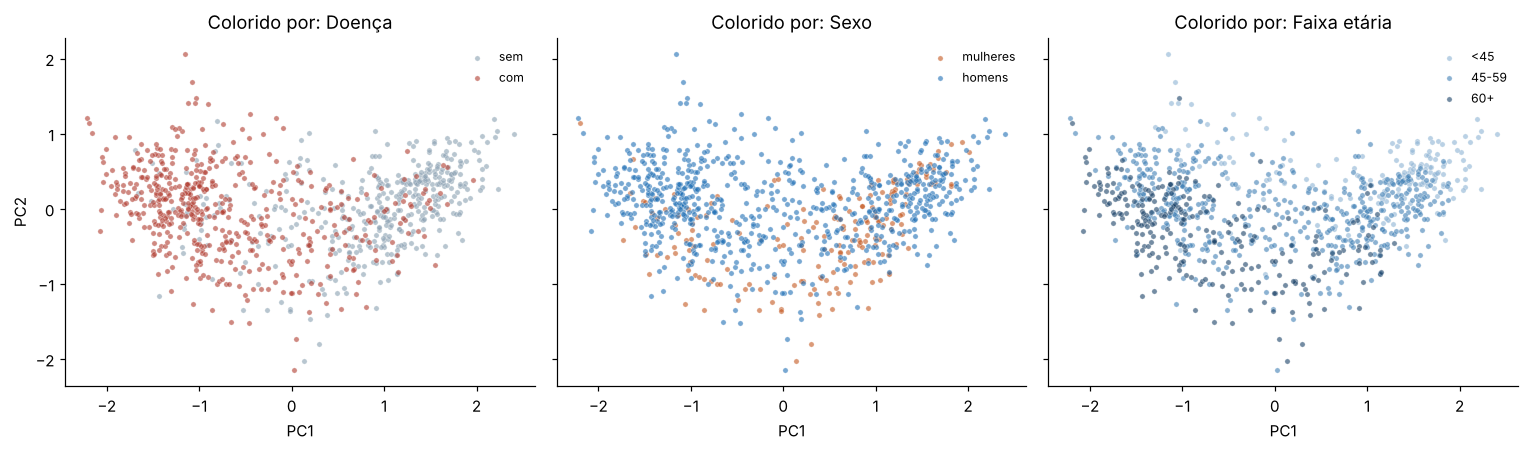

In [ ]:
X, y_, d_, num = make_dataset(MAIN_TREATMENT)
pipe = make_pipe("MLP", num, SEED).fit(X, y_)
clf = pipe.named_steps["clf"]
a = pipe.named_steps["pre"].transform(X)
for W, b in zip(clf.coefs_[:-1], clf.intercepts_[:-1]):
    a = np.maximum(a @ W + b, 0)
Z = PCA(n_components=2, random_state=SEED).fit(a)
pc = Z.transform(a)
print("Variância explicada (2 PCs): %.0f%%" % (100 * Z.explained_variance_ratio_.sum()))

fig, axs = plt.subplots(1, 3, figsize=(14, 4.2), sharex=True, sharey=True)
panels = [("Doença", y_, {0: ("#8aa0b2", "sem"), 1: ("#b03a2e", "com")}),
          ("Sexo", d_.Sex.values, {"F": (SEXC["F"], "mulheres"), "M": (SEXC["M"], "homens")}),
          ("Faixa etária", d_.AgeBand.values, {"<45": ("#8db3d4", "<45"), "45-59": ("#3f7fb5", "45-59"), "60+": ("#173f66", "60+")})]
for ax, (title, vals, cmap) in zip(axs, panels):
    for k, (c, lab) in cmap.items():
        m = vals == k
        ax.scatter(pc[m, 0], pc[m, 1], s=12, alpha=0.6, color=c, label=lab, edgecolor="white", linewidth=0.3)
    ax.set_title(f"Colorido por: {title}")
    ax.legend(frameon=False, fontsize=8)
    ax.set_xlabel("PC1")
axs[0].set_ylabel("PC2")
plt.tight_layout()
plt.show()

## 8. Conclusões

*(Números da execução com `SEED = 42`; ICs de 95% entre colchetes.)*

### Resposta curta

A rede **ordena o risco igualmente bem** para mulheres e homens (AUC 0,91 nos dois), mas, com um limiar único de 0,5, **opera em pontos diferentes conforme o público**: perde mais casos de doença em mulheres e em pacientes jovens, e sinaliza como doentes muitos pacientes saudáveis entre os idosos. Já **o que a rede usa para decidir é praticamente o mesmo em todos os públicos**: nenhuma diferença de importância entre mulheres e homens se distingue de zero.

### A. Ela se comporta da mesma forma?

- **Sexo, discriminação:** AUC de 0,91 [0,86–0,95] nas mulheres e 0,91 [0,89–0,93] nos homens (diferença 0,001, IC [−0,05; 0,05]). Não há evidência de diferença.
- **Sexo, ponto de operação:** a sensibilidade é 0,76 nas mulheres e 0,89 nos homens (diferença −0,13, IC [−0,25; −0,02]). Em termos de falsos negativos, a rede deixa de detectar cerca de **24% das mulheres com doença contra 11% dos homens**. A especificidade vai no sentido oposto (0,85 × 0,78), mas o IC da diferença inclui 0. A rede também **superestima o risco médio das mulheres** (probabilidade média prevista 0,36 × prevalência observada 0,26), enquanto nos homens fica próxima (0,60 × 0,63).
- **Idade:** o AUC cai de 0,95 (<45) para 0,91 (45–59) e 0,87 (60+); a diferença <45 × 60+ é pequena, mas distinguível de zero (0,07, IC [0,01; 0,14]). O efeito mais forte está no limiar fixo: a sensibilidade sobe de 0,69 para 0,87 e 0,95, e a especificidade **despenca de 0,95 para 0,80 e 0,53**. Ou seja, nos idosos 47% dos pacientes sem doença são sinalizados como doentes, e nos jovens um terço dos doentes passa despercebido. Isso acompanha a prevalência de cada faixa (33% → 54% → 73%): a rede incorporou a taxa-base de cada grupo.
- **Implicação:** como a capacidade de ordenar o risco é a mesma, o problema é de calibração e de escolha do limiar, não de falta de informação. Um limiar ou uma recalibração por público seria o próximo passo (não testado aqui).
- **Sexo × idade:** o cruzamento é exploratório. Há só 5 mulheres com doença abaixo de 45 anos, e as métricas desse grupo não são interpretáveis.

### B. O que ela aprendeu em cada público?

- **Variáveis dominantes, iguais em todos os públicos:** `ST_Slope` (queda de AUC de 0,025 no geral) e `ChestPainType` (0,014), seguidas de `FastingBS`, `Oldpeak` e `ExerciseAngina`. `ST_Slope` aparece entre as 3 mais importantes em 100% das repetições, em todos os públicos.
- **Mulheres × homens:** todos os ICs da diferença de importância incluem 0, e a concordância de postos é alta (Spearman 0,77 na MLP; 0,81 na logística). Alguns sinais (como `FastingBS`, 0,019 nas mulheres × 0,005 nos homens) têm IC largo e devem ser tratados como hipóteses. A regressão logística por sexo mostra os mesmos padrões clínicos: `ST_Slope` ascendente protege (−1,28 e −1,04) e `ST_Slope` plano e dor assintomática elevam o risco (cerca de +1 a +1,3).
- **Sexo como variável:** sua importância é ~0 dentro de cada sexo e 0,009 no conjunto. Ele desloca o risco-base entre os grupos, mas não muda como as demais variáveis são usadas dentro de cada um.
- **Idade como variável:** importância ≤ 0 em todos os públicos. A rede não usa a idade além do que já está contido nas outras variáveis, o que é um achado em si para quem esperava um modelo "por idade".
- **Faixas etárias:** concordância menor entre <45 e 60+ (Spearman 0,66), com indícios de que `Oldpeak` e `ExerciseAngina` pesam mais nos mais velhos. Não há IC para essas diferenças, então é exploratório.
- **Rede × regressão logística:** concordância de 0,85 nos postos (0,94 em 60+, 0,69 em <45) e AUC praticamente igual (0,918 × 0,922). A MLP não trouxe ganho preditivo, e o "conhecimento" extraído dela é, em essência, linear.
- **Camada oculta:** o primeiro componente principal separa doença × não doença, com gradiente de idade ao longo do mesmo eixo; as mulheres se concentram na região de menor risco.
- **Redes treinadas por sexo:** a rede só com homens equivale à global (AUC 0,90 × 0,91). A rede **só com mulheres cai para 0,78** (global: 0,91), mas a regressão logística só com mulheres chega a 0,90. Logo, a MLP é "faminta por dados" e se beneficia de ver os homens; a queda reflete o tamanho da amostra (≈ 154 pacientes de treino por fold) e não uma diferença biológica. Para esse público, o treino conjunto é melhor que um modelo separado.

### C. Colesterol = 0

Os três tratamentos mudam pouco o desempenho (AUC 0,918 a 0,922), e a importância do colesterol é ~0 em todos eles; a coluna "colesterol ausente" pesa só 0,007. O atalho temido quase não é usado, provavelmente porque 126 dos 172 zeros são pacientes com dor assintomática, informação que `ChestPainType` já carrega. As conclusões são robustas a essa escolha.

### Ressalvas na leitura

As quedas de AUC por permutação são pequenas (≤ 0,035) porque as variáveis são redundantes entre si; importância baixa **não** significa irrelevância clínica (idade e frequência cardíaca máxima, por exemplo). As diferenças encontradas são de associação nesta base, e o alvo é doença cardíaca diagnosticada em pacientes encaminhados, não infarto.

## 9. Limitações

- **Alvo e população:** `HeartDisease` é doença cardíaca diagnosticada por angiografia em pacientes encaminhados ao exame, não infarto e não risco populacional. A base reúne hospitais com protocolos distintos (a versão usada não informa o hospital).
- **Tamanho:** 193 mulheres (50 positivas) e só 5 mulheres positivas com menos de 45 anos. Resultados nesses subgrupos são exploratórios.
- **Associação, não causalidade:** importância por permutação mede dependência do modelo em uma variável, não efeito clínico. Variáveis correlacionadas dividem importância entre si.
- **Colesterol = 0:** a ausência é informativa (88% de doença entre os zeros). A análise principal imputa a mediana; a seção 6 mostra a sensibilidade a essa escolha.
- **Limiar único:** o limiar de 0,5 não foi otimizado por público. Diferenças de sensibilidade podem refletir também diferenças de prevalência (63% nos homens × 26% nas mulheres) e de calibração.
- **IC por bootstrap de pacientes** sobre previsões médias de 10 repetições: reflete a variabilidade amostral dos pacientes, mas não incorpora a incerteza de escolher hiperparâmetros (arquitetura fixa, sem busca).

analisar os pacientes diagnosticados com doença cardíaca e verificar se a rede neural se comporta da mesma forma entre diferentes públicos

In [7]:
!pip install tensorflow scikeras -q

In [16]:
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    roc_auc_score,
    roc_curve
)

from sklearn.inspection import permutation_importance

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

from traducao import (
    COLUNAS, TIPOS, UNIDADES, traduzir_dataframe, dicionario_dados, rotulo, ordem_classes,
)

In [11]:
from google.colab import drive
drive.mount('/content/drive')

df = pd.read_csv("heart.csv") # base de dados

print(df.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
   Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  MaxHR ExerciseAngina  Oldpeak ST_Slope  HeartDisease
0   40   M           ATA        140          289          0     Normal    172              N      0.0       Up             0
1   49   F           NAP        160          180          0     Normal    156              N      1.0     Flat             1
2   37   M           ATA        130          283          0         ST     98              N      0.0       Up             0
3   48   F           ASY        138          214          0     Normal    108              Y      1.5     Flat             1
4   54   M           NAP        150          195          0     Normal    122              N      0.0       Up             0


In [17]:
df = traduzir_dataframe(df)
df.head()

,idade,sexo,tipo_dor_peito,pressao_repouso,colesterol,glicemia_jejum,ecg_repouso,freq_cardiaca_max,angina_exercicio,depressao_st,inclinacao_st,doenca_cardiaca
0,40,Masculino,Angina atípica (ATA),140,289,≤ 120 mg/dL (0),Normal,172,Não (N),0.0,Ascendente (Up),Sem doença (0)
1,49,Feminino,Dor não anginosa (NAP),160,180,≤ 120 mg/dL (0),Normal,156,Não (N),1.0,Plana (Flat),Com doença (1)
2,37,Masculino,Angina atípica (ATA),130,283,≤ 120 mg/dL (0),Anomalia de ST-T (ST),98,Não (N),0.0,Ascendente (Up),Sem doença (0)
3,48,Feminino,Assintomática (ASY),138,214,≤ 120 mg/dL (0),Normal,108,Sim (Y),1.5,Plana (Flat),Com doença (1)
4,54,Masculino,Dor não anginosa (NAP),150,195,≤ 120 mg/dL (0),Normal,122,Não (N),0.0,Ascendente (Up),Sem doença (0)


In [18]:
print(df.shape)

df.info()

df.describe()

(918, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   idade              918 non-null    int64  
 1   sexo               918 non-null    object 
 2   tipo_dor_peito     918 non-null    object 
 3   pressao_repouso    918 non-null    int64  
 4   colesterol         918 non-null    int64  
 5   glicemia_jejum     918 non-null    object 
 6   ecg_repouso        918 non-null    object 
 7   freq_cardiaca_max  918 non-null    int64  
 8   angina_exercicio   918 non-null    object 
 9   depressao_st       918 non-null    float64
 10  inclinacao_st      918 non-null    object 
 11  doenca_cardiaca    918 non-null    object 
dtypes: float64(1), int64(4), object(7)
memory usage: 86.2+ KB


,idade,pressao_repouso,colesterol,freq_cardiaca_max,depressao_st
count,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,136.809368,0.887364
std,9.432617,18.514154,109.384145,25.460334,1.066570
min,28.000000,0.000000,0.000000,60.000000,-2.600000
25%,47.000000,120.000000,173.250000,120.000000,0.000000
50%,54.000000,130.000000,223.000000,138.000000,0.600000
75%,60.000000,140.000000,267.000000,156.000000,1.500000
max,77.000000,200.000000,603.000000,202.000000,6.200000


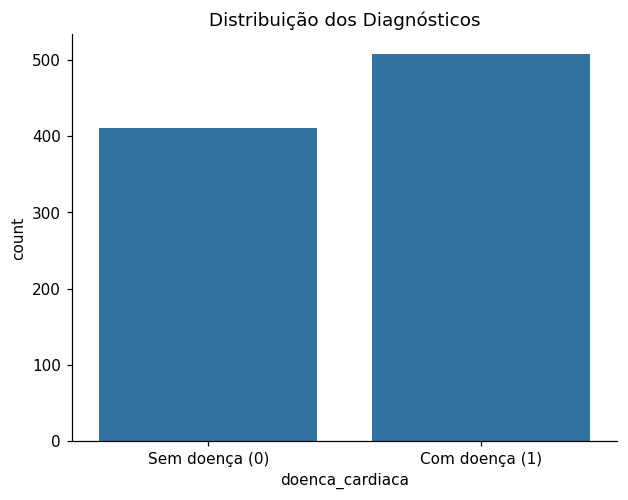

doenca_cardiaca
Com doença (1)    508
Sem doença (0)    410
Name: count, dtype: int64


In [19]:
#distribuição da variavel alvo
sns.countplot(data=df, x='doenca_cardiaca')
plt.title("Distribuição dos Diagnósticos")
plt.show()

print(df['doenca_cardiaca'].value_counts())

In [34]:
#Perfil dos pacientes com doença cardíaca
doentes = df[df['doenca_cardiaca']==1]

print("IDADE MÉDIA")
print(doentes['idade'].mean())

print("\nSEXO")
print(doentes['sexo'].value_counts(normalize=True)*100)

print("\nTIPO DE DOR")
print(doentes['tipo_dor_peito'].value_counts(normalize=True)*100)

print("\nANGINA DE EXERCÍCIO")
print(doentes['angina_exercicio'].value_counts(normalize=True)*100)

print("\nST SLOPE")
print(doentes['depressao_st'].value_counts(normalize=True)*100)

IDADE MÉDIA
nan

SEXO
Series([], Name: proportion, dtype: float64)

TIPO DE DOR
Series([], Name: proportion, dtype: float64)

ANGINA DE EXERCÍCIO
Series([], Name: proportion, dtype: float64)

ST SLOPE
Series([], Name: proportion, dtype: float64)


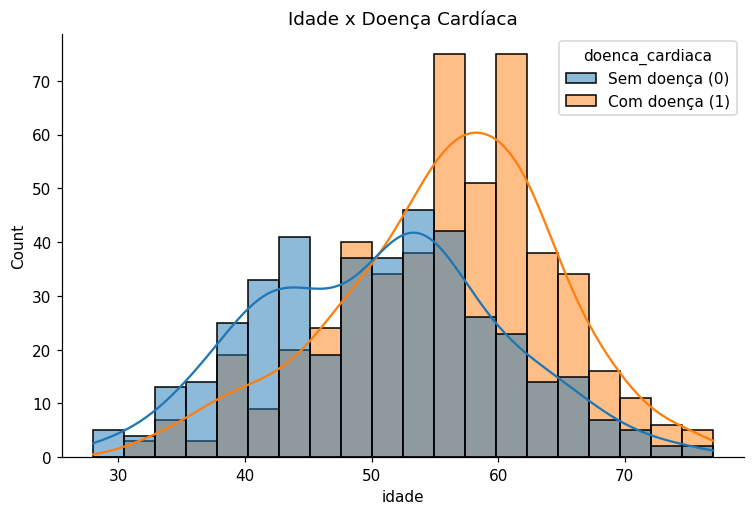

In [35]:
#Idade por doença
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x="idade",
    hue="doenca_cardiaca",
    bins=20,
    kde=True
)

plt.title("Idade x Doença Cardíaca")
plt.show()

In [36]:
pd.crosstab(
    df["tipo_dor_peito"],
    df["doenca_cardiaca"],
    normalize='index'
)*100

doenca_cardiaca,Com doença (1),Sem doença (0)
tipo_dor_peito,,
Angina atípica (ATA),13.872832,86.127168
Angina típica (TA),43.478261,56.521739
Assintomática (ASY),79.032258,20.967742
Dor não anginosa (NAP),35.467980,64.532020


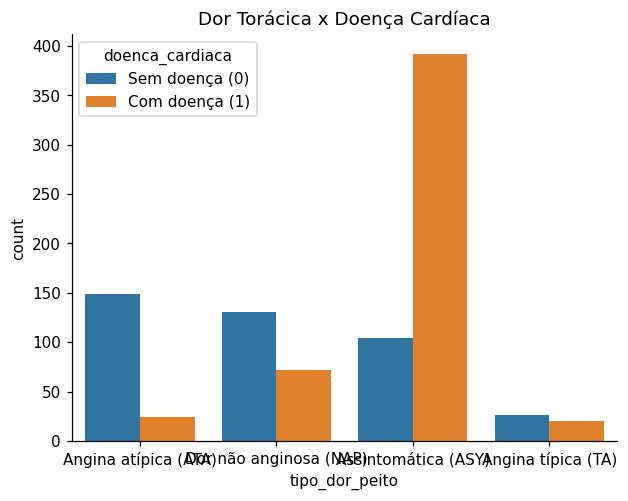

In [37]:
sns.countplot(
    data=df,
    x='tipo_dor_peito',
    hue='doenca_cardiaca'
)

plt.title('Dor Torácica x Doença Cardíaca')
plt.show()

In [38]:
pd.crosstab(
    df["angina_exercicio"],
    df["doenca_cardiaca"],
    normalize='index'
)*100

doenca_cardiaca,Com doença (1),Sem doença (0)
angina_exercicio,,
Não (N),35.100548,64.899452
Sim (Y),85.175202,14.824798


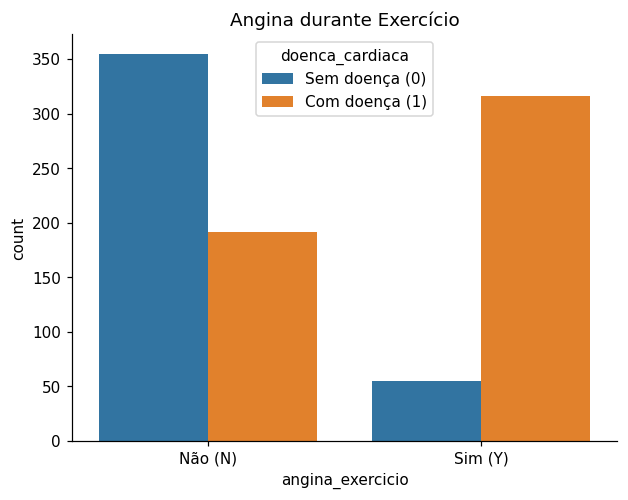

In [39]:
sns.countplot(
    data=df,
    x='angina_exercicio',
    hue='doenca_cardiaca'
)

plt.title("Angina durante Exercício")
plt.show()

In [43]:

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.inspection import permutation_importance

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# ============================================================
# 3. CARREGAR A BASE
# ============================================================

uploaded = files.upload()

df = pd.read_csv("heart.csv")

# ============================================================
# 4. VISÃO GERAL DA BASE
# ============================================================

print("="*50)
print("DIMENSÃO DA BASE")
print("="*50)

print(df.shape)

print("\n")

print("="*50)
print("INFORMAÇÕES")
print("="*50)

print(df.info())

print("\n")

print("="*50)
print("ESTATÍSTICAS")
print("="*50)

print(df.describe())

Saving heart.csv to heart (1).csv
DIMENSÃO DA BASE
(918, 12)


INFORMAÇÕES
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB
None


ESTATÍSTICAS
              Age   RestingBP  Cholesterol   FastingBS       MaxHR     Oldpeak  HeartDisease
count  918.000

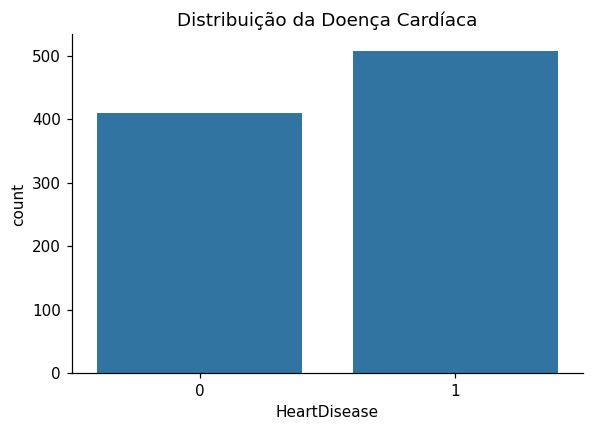

HeartDisease
1    508
0    410
Name: count, dtype: int64


PERFIL DOS PACIENTES COM DOENÇA

Sexo (%)
Sex
M    90.16
F     9.84
Name: proportion, dtype: float64

Tipo de Dor Torácica (%)
ChestPainType
ASY    77.17
NAP    14.17
ATA     4.72
TA      3.94
Name: proportion, dtype: float64

Angina de Exercício (%)
ExerciseAngina
Y    62.2
N    37.8
Name: proportion, dtype: float64

ST Slope (%)
ST_Slope
Flat    75.00
Up      15.35
Down     9.65
Name: proportion, dtype: float64


In [44]:
# ============================================================
# 5. DISTRIBUIÇÃO DA VARIÁVEL ALVO
# ============================================================

plt.figure(figsize=(6,4))

sns.countplot(
    data=df,
    x='HeartDisease'
)

plt.title("Distribuição da Doença Cardíaca")
plt.show()

print(df["HeartDisease"].value_counts())

# ============================================================
# 6. PERFIL DOS PACIENTES COM DOENÇA CARDÍACA
# ============================================================

doentes = df[df["HeartDisease"] == 1]

print("\n")
print("="*50)
print("PERFIL DOS PACIENTES COM DOENÇA")
print("="*50)

print("\nSexo (%)")

print(
    round(
        doentes["Sex"].value_counts(normalize=True)*100,
        2
    )
)

print("\nTipo de Dor Torácica (%)")

print(
    round(
        doentes["ChestPainType"].value_counts(normalize=True)*100,
        2
    )
)

print("\nAngina de Exercício (%)")

print(
    round(
        doentes["ExerciseAngina"].value_counts(normalize=True)*100,
        2
    )
)

print("\nST Slope (%)")

print(
    round(
        doentes["ST_Slope"].value_counts(normalize=True)*100,
        2
    )
)


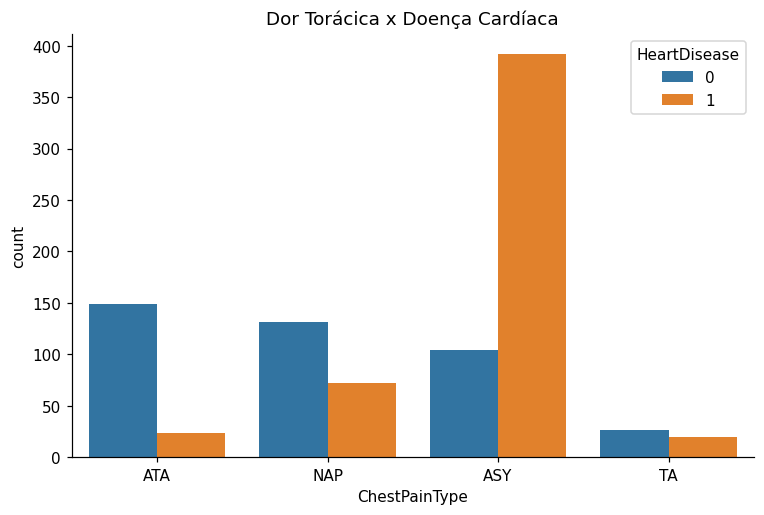

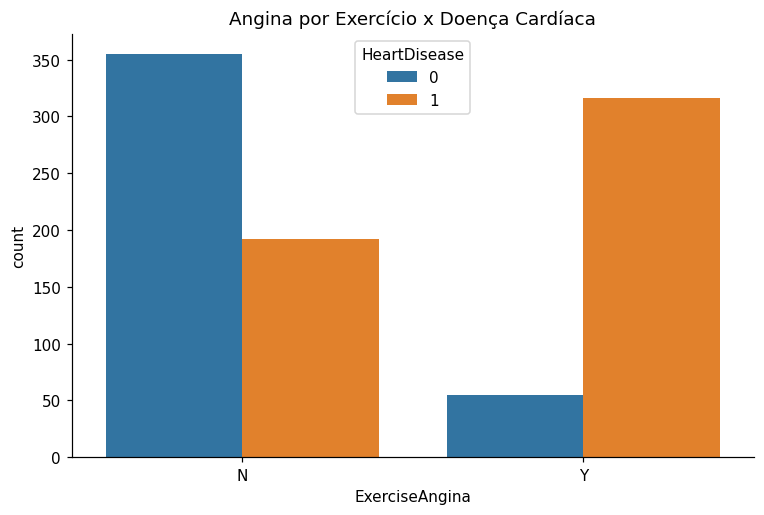

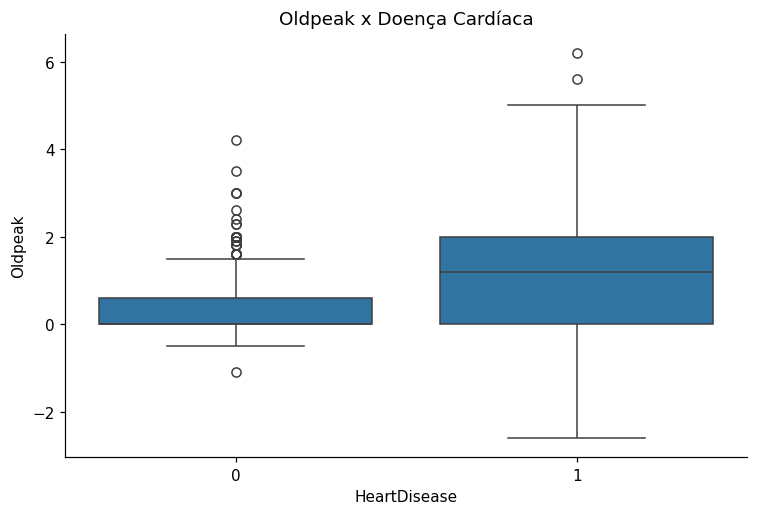

In [45]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x='ChestPainType',
    hue='HeartDisease'
)

plt.title("Dor Torácica x Doença Cardíaca")

plt.show()

# ------------------------------------------------------------

plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x='ExerciseAngina',
    hue='HeartDisease'
)

plt.title("Angina por Exercício x Doença Cardíaca")

plt.show()

# ------------------------------------------------------------

plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x='HeartDisease',
    y='Oldpeak'
)

plt.title("Oldpeak x Doença Cardíaca")

plt.show()

# ============================================================
# 8. REMOVER AGE DA MODELAGEM
# ============================================================

X = df.drop(
    columns=[
        "HeartDisease",
        "Age"          # <- REMOVIDA
    ]
)

y = df["HeartDisease"]

# ============================================================
# 9. VARIÁVEIS
# ============================================================

categoricas = [
    "Sex",
    "ChestPainType",
    "RestingECG",
    "ExerciseAngina",
    "ST_Slope"
]

numericas = [
    "RestingBP",
    "Cholesterol",
    "FastingBS",
    "MaxHR",
    "Oldpeak"
]

In [47]:
# ============================================================
# 10. PRÉ-PROCESSAMENTO
# ============================================================

preprocessador = ColumnTransformer(

    transformers=[
        (
            "cat",
            OneHotEncoder(drop="first"),
            categoricas
        ),

        (
            "num",
            StandardScaler(),
            numericas
        )

    ]
)

# ============================================================
# 11. TREINO E TESTE
# ============================================================

X_train_original, X_test_original, y_train, y_test = train_test_split(

    X,
    y,

    test_size=0.20,

    random_state=42,

    stratify=y

)

# ============================================================
# 12. TRANSFORMAÇÃO DOS DADOS
# ============================================================

X_train = preprocessador.fit_transform(X_train_original)

X_test = preprocessador.transform(X_test_original)

# ============================================================
# 13. REDE NEURAL
# ============================================================

modelo = Sequential([

    Dense(
        32,
        activation='relu',
        input_shape=(X_train.shape[1],)
    ),

    Dense(
        16,
        activation='relu'
    ),

    Dense(
        1,
        activation='sigmoid'
    )

])

Epoch 1/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.4600 - loss: 0.6890 - val_accuracy: 0.5918 - val_loss: 0.6563
Epoch 2/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6763 - loss: 0.6227 - val_accuracy: 0.7415 - val_loss: 0.6099
Epoch 3/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7564 - loss: 0.5674 - val_accuracy: 0.7959 - val_loss: 0.5663
Epoch 4/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8007 - loss: 0.5103 - val_accuracy: 0.8163 - val_loss: 0.5218
Epoch 5/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8296 - loss: 0.4544 - val_accuracy: 0.8027 - val_loss: 0.4852
Epoch 6/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8450 - loss: 0.4076 - val_accuracy: 0.8027 - val_loss: 0.4655
Epoch 7/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8501 - loss: 0.3802 - val_accuracy: 0.8095 - val_loss: 0.4557
Epoch 8/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8552 - loss: 0.3607 - val_accuracy: 0.8231 - 

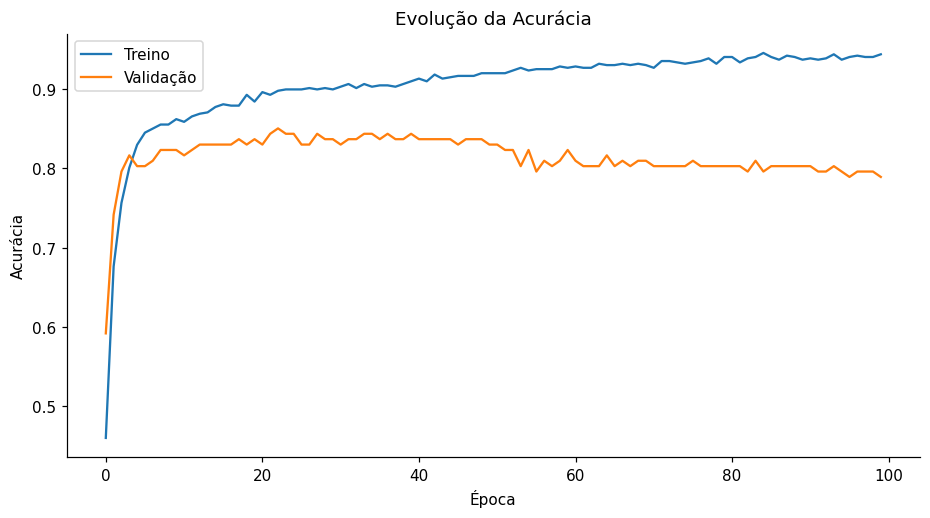

In [48]:
# ============================================================
# 14. COMPILAÇÃO
# ============================================================

modelo.compile(

    optimizer='adam',

    loss='binary_crossentropy',

    metrics=['accuracy']

)

# ============================================================
# 15. TREINAMENTO
# ============================================================

historico = modelo.fit(

    X_train,
    y_train,

    epochs=100,

    batch_size=32,

    validation_split=0.2,

    verbose=1

)

# ============================================================
# 16. CURVA DE APRENDIZAGEM
# ============================================================

plt.figure(figsize=(10,5))

plt.plot(
    historico.history["accuracy"],
    label="Treino"
)

plt.plot(
    historico.history["val_accuracy"],
    label="Validação"
)

plt.title("Evolução da Acurácia")

plt.xlabel("Época")

plt.ylabel("Acurácia")

plt.legend()

plt.show()

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step


RESULTADOS
ACURÁCIA: 0.8696
ROC AUC: 0.9362

RELATÓRIO DE CLASSIFICAÇÃO

              precision    recall  f1-score   support

           0       0.88      0.82      0.85        82
           1       0.86      0.91      0.89       102

    accuracy                           0.87       184
   macro avg       0.87      0.86      0.87       184
weighted avg       0.87      0.87      0.87       184



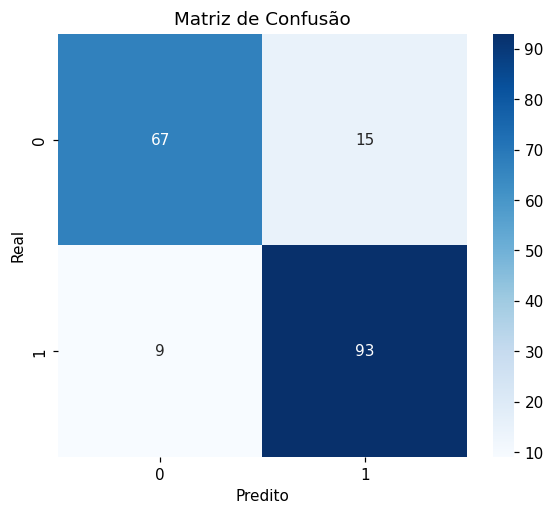

In [50]:
probabilidades = modelo.predict(X_test)
predicoes = (
    probabilidades > 0.5
).astype(int)

# ============================================================
# 18. MÉTRICAS
# ============================================================

print("\n")
print("="*50)
print("RESULTADOS")
print("="*50)

acc = accuracy_score(
    y_test,
    predicoes
)

auc = roc_auc_score(
    y_test,
    probabilidades
)

print("ACURÁCIA:", round(acc,4))

print("ROC AUC:", round(auc,4))

print("\nRELATÓRIO DE CLASSIFICAÇÃO\n")

print(
    classification_report(
        y_test,
        predicoes
    )
)

# ============================================================
# 19. MATRIZ DE CONFUSÃO
# ============================================================

cm = confusion_matrix(
    y_test,
    predicoes
)

plt.figure(figsize=(6,5))

sns.heatmap(

    cm,

    annot=True,

    fmt='d',

    cmap='Blues'

)

plt.title("Matriz de Confusão")

plt.xlabel("Predito")

plt.ylabel("Real")

plt.show()

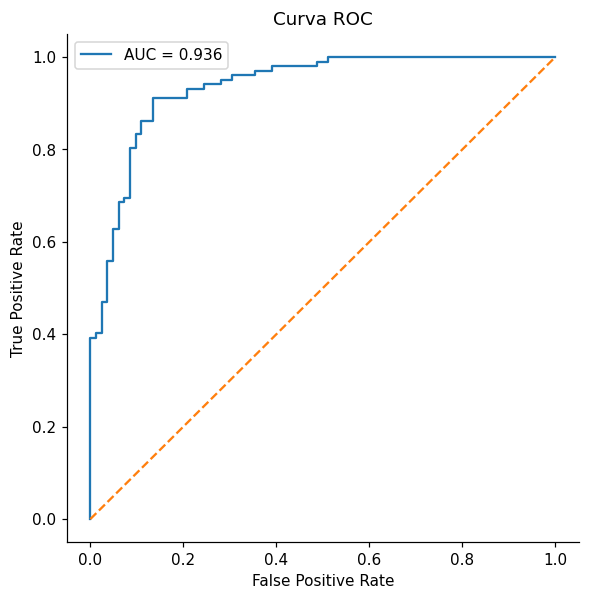



DESEMPENHO POR SEXO
Sexo M: 0.8562
Sexo F: 0.9211


In [52]:
# ============================================================
# 20. CURVA ROC
# ============================================================

fpr, tpr, thresholds = roc_curve(
    y_test,
    probabilidades
)

plt.figure(figsize=(6,6))

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {auc:.3f}"
)

plt.plot(
    [0,1],
    [0,1],
    '--'
)

plt.legend()

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("Curva ROC")

plt.show()

# ============================================================
# 21. A REDE É IGUAL PARA HOMENS E MULHERES?
# ============================================================

resultado = X_test_original.copy()

resultado["REAL"] = y_test.values

resultado["PREDITO"] = predicoes.flatten()

print("\n")
print("="*50)
print("DESEMPENHO POR SEXO")
print("="*50)

for sexo in resultado["Sex"].unique():

    grupo = resultado[
        resultado["Sex"] == sexo
    ]

    acuracia = accuracy_score(
        grupo["REAL"],
        grupo["PREDITO"]
    )

    print(
        f"Sexo {sexo}: {acuracia:.4f}"
    )




TOP 15 VARIÁVEIS
         Variavel  Importancia
9        ST_Slope     0.118478
1   ChestPainType     0.063043
3     Cholesterol     0.055978
0             Sex     0.038043
4       FastingBS     0.032065
2       RestingBP     0.031522
8         Oldpeak     0.028804
6           MaxHR     0.028261
7  ExerciseAngina     0.008696
5      RestingECG     0.005435


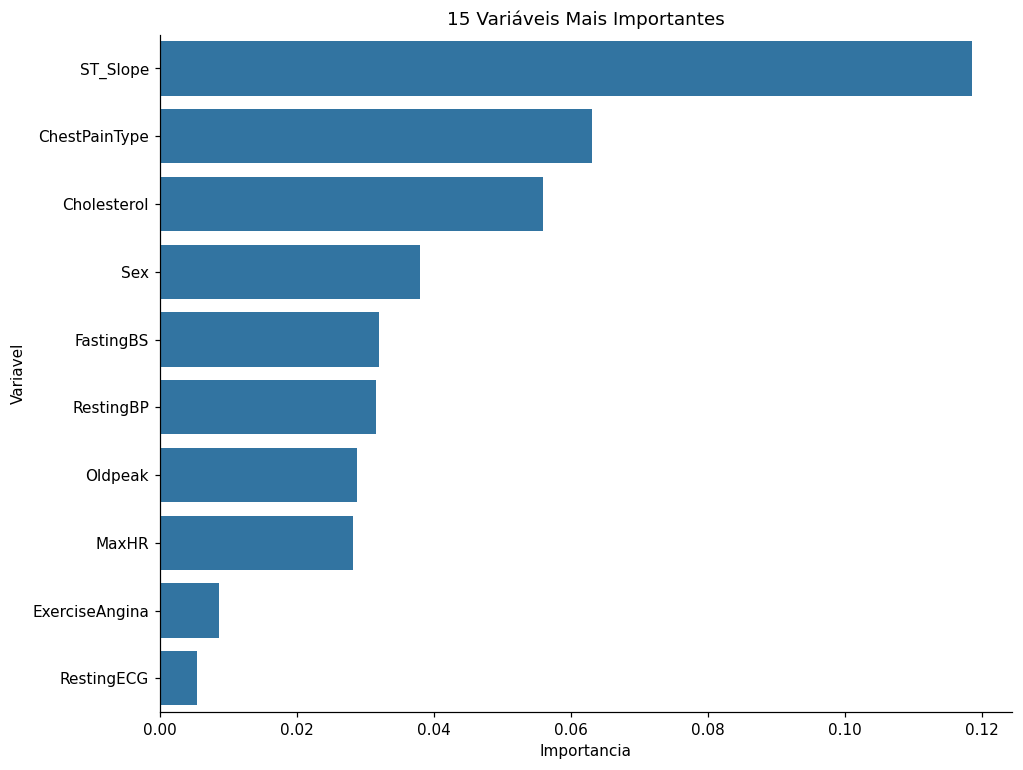

In [54]:
# ============================================================
# 22. IMPORTÂNCIA DAS VARIÁVEIS
# ============================================================

mlp = MLPClassifier(

    hidden_layer_sizes=(32,16),

    max_iter=1000,

    random_state=42

)

pipe = Pipeline([

    ('prep', preprocessador),

    ('mlp', mlp)
])

pipe.fit(
    X_train_original,
    y_train
)

resultado_importancia = permutation_importance(

    pipe,

    X_test_original,

    y_test,

    scoring='accuracy',

    n_repeats=10,

    random_state=42

)


nomes_variaveis = X_test_original.columns

importancias = pd.DataFrame({

    "Variavel": nomes_variaveis,

    "Importancia":
        resultado_importancia.importances_mean

})

importancias = importancias.sort_values(

    by='Importancia',

    ascending=False

)

print("\n")
print("="*50)
print("TOP 15 VARIÁVEIS")
print("="*50)

print(importancias.head(15))

plt.figure(figsize=(10,8))

sns.barplot(

    data=importancias.head(15),

    x='Importancia',

    y='Variavel'

)

plt.title(
    '15 Variáveis Mais Importantes'
)

plt.show()

In [56]:
# ============================================================
# 23. CONCLUSÃO AUTOMÁTICA
# ============================================================

print("\n")
print("="*60)
print("CONCLUSÃO")
print("="*60)

print(
"""
Este experimento removeu completamente a variável AGE.

Avaliar a acurácia e caso esteja próxima da obtida no modelo
original, conclui-se que a idade não é um fator
essencial para a identificação da doença cardíaca nesta
base específica.

Isso indicaria que variáveis relacionadas ao:
- comportamento cardíaco durante esforço,
- alterações do segmento ST,
- angina induzida por exercício,
- eletrocardiograma,

são suficientes para caracterizar grande parte dos
pacientes encaminhados à angiografia.
"""
)



CONCLUSÃO

Este experimento removeu completamente a variável AGE.

Avaliar a acurácia e caso esteja próxima da obtida no modelo
original, conclui-se que a idade não é um fator
essencial para a identificação da doença cardíaca nesta
base específica.

Isso indicaria que variáveis relacionadas ao:
- comportamento cardíaco durante esforço,
- alterações do segmento ST,
- angina induzida por exercício,
- eletrocardiograma,

são suficientes para caracterizar grande parte dos
pacientes encaminhados à angiografia.

